# Correcting k-mer ANI estimates for regional mutation-rate heterogeneity



In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##  Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from google.colab import drive
from datetime import datetime
import os

pd.set_option("display.width", 200)
rng = np.random.default_rng(42)

In [3]:
PROJECT = "/content/drive/MyDrive/CMPS355_ANI_Project"
RESULTS = f"{PROJECT}/results"
DATA    = f"{PROJECT}/data"
os.makedirs(RESULTS, exist_ok=True)
os.makedirs(DATA, exist_ok=True)

def save_results(df, name):
    stamp = datetime.now().strftime("%Y%m%d_%H%M")
    path = f"{RESULTS}/{name}_{stamp}.csv"
    df.to_csv(path, index=False)
    print("Saved:", path)

In [4]:
def run_or_load(name, settings, seed, force=False):
    path = f"{RESULTS}/{name}.csv"
    if os.path.exists(path) and not force:
        print("Loaded saved results:", path)
        return pd.read_csv(path)
    global rng
    rng = np.random.default_rng(seed)            # fixed seed -> same pairs every time
    df = run_experiment(settings)
    df.to_csv(path, index=False)
    print("Ran and saved:", path)
    return df

In [5]:
GENOME_LEN  = 1_000_000                    # 1 Mb random "bacterial" genome
REGION_LEN  = 5_000                        # one region ~ a few genes; all sites in a region share one rate
N_REGIONS   = GENOME_LEN // REGION_LEN
KS          = np.arange(15, 32, 2)         # k = 15, 17, ..., 31 for the multi-k methods
K_MASH      = 21                           # Mash / sourmash default
TARGET_ANIS = np.arange(0.80, 0.99, 0.02)  # true ANI values to simulate
REPLICATES  = 2

# genome A: the reference every simulated genome B is compared against
genome_A = rng.integers(0, 4, GENOME_LEN, dtype=np.uint8)

### Simulating genome pairs
Each region gets one mutation rate (mean 1) from a **rate pattern**, scaled to the target divergence. Optionally, a fraction of B's regions is replaced by unrelated sequence (genes only B has). True ANI is computed over shared regions only.

In [6]:
# ---------------- rate patterns: one rate per region, mean = 1 ----------------
def rates_uniform(n):
    return np.ones(n)

def rates_gamma(alpha):
    return lambda n: rng.gamma(alpha, 1 / alpha, n)

def rates_two_class(n, frac_fast=0.3, fold=5):
    r = np.where(rng.random(n) < frac_fast, fold, 1.0)
    return r / r.mean()

def rates_wave(n, fold=4, waves=2):
    x = np.arange(n) / n
    amp = (fold - 1) / (fold + 1)                     # gives max/min = fold
    r = 1 + amp * np.sin(2 * np.pi * waves * x + rng.uniform(0, 2 * np.pi))
    return r / r.mean()

# ---------------- make one genome pair ----------------
def make_pair(mean_p, rate_fn, gene_diff=0.0):
    """Mutate genome A into B. Returns B, true ANI (shared regions only) and true s."""
    rates = rate_fn(N_REGIONS)
    p_site = np.clip(np.repeat(mean_p * rates, REGION_LEN), 0, 0.75)
    hit = rng.random(GENOME_LEN) < p_site
    B = genome_A.copy()
    B[hit] = (genome_A[hit] + rng.integers(1, 4, hit.sum())) % 4   # always a different base

    # gene-content difference: replace some of B's regions with unrelated sequence
    replaced = rng.choice(N_REGIONS, int(round(gene_diff * N_REGIONS)), replace=False)
    is_replaced = np.isin(np.arange(GENOME_LEN) // REGION_LEN, replaced)
    B[is_replaced] = rng.integers(0, 4, is_replaced.sum(), dtype=np.uint8)

    true_ani = 1 - hit[~is_replaced].mean()
    true_s = 1 - is_replaced.mean()
    return B, true_ani, true_s

### Counting shared k-mers
For each k we compute the fraction of A's k-mers that also appear in B, minus the matches expected by pure chance (this matters at small k).

In [7]:
def kmer_set(seq, k):
    n = len(seq) - k + 1
    vals = np.zeros(n, dtype=np.uint64)
    for j in range(k):
        vals = (vals << np.uint64(2)) | seq[j:j + n].astype(np.uint64)
    return np.unique(vals)

kmers_A_by_k = {k: kmer_set(genome_A, k) for k in KS}   # computed once

def shared_fractions(B):
    out = []
    for k in KS:
        kA = kmers_A_by_k[k]
        kB = kmer_set(B, k)
        shared = np.intersect1d(kA, kB, assume_unique=True).size
        chance = kA.size * kB.size / 4.0 ** k
        out.append(max(shared - chance, 1) / kA.size)
    return np.array(out)

### Estimators
- **Mash formula (k = 21):** current practice, $\text{ANI} = 1 + \frac{1}{k}\ln\frac{2J}{1+J}$.
- **Multi-k uniform (control):** straight line $\log C(k) = \log s + k \log(\text{ANI})$.
- **Multi-k gamma (ours):** $\log C(k) = \log s - \alpha \log(1 + k d/\alpha)$, then $\text{ANI} = (1 + d/\alpha)^{-\alpha}$.

In [8]:
def est_mash(C):
    C21 = C[KS == K_MASH][0]
    J = C21 / (2 - C21)                        # containment -> Jaccard (equal-size genomes)
    return 1 + np.log(2 * J / (1 + J)) / K_MASH

def est_uniform(C):
    slope, intercept = np.polyfit(KS, np.log(C), 1)
    return np.exp(slope), np.exp(intercept), -slope        # ANI, s, d

def gamma_model(k, s, d, alpha):
    return np.log(s) - alpha * np.log1p(k * d / alpha)

def est_gamma(C):
    y = np.log(C)
    _, s0, d0 = est_uniform(C)                 # straight-line fit gives starting s and d
    best = None
    for a0 in [0.3, 1, 5, 50]:                 # several starting alphas, keep the best fit
        try:
            p, _ = curve_fit(gamma_model, KS, y,
                             p0=[min(s0, 0.99), max(d0, 1e-4), a0],
                             bounds=([1e-6, 1e-6, 0.01], [1, 3, 1000]), maxfev=20000)
            err = np.sum((gamma_model(KS, *p) - y) ** 2)
            if best is None or err < best[1]:
                best = (p, err)
        except RuntimeError:
            pass
    s, d, alpha = best[0]
    return (1 + d / alpha) ** (-alpha), s, alpha

MASH, UNIF, GAMMA = "Mash formula (k = 21)", "Multi-k uniform (control)", "Multi-k gamma (ours)"
COLORS = {MASH: "#999999", UNIF: "#2b8cbe", GAMMA: "#d7191c"}

### Running and summarising an experiment
`run_experiment` simulates every setting, applies all three estimators and returns one table. The plotting and summary helpers are shared by all experiments.

In [9]:
def run_experiment(settings):
    """settings: {name: (rate_fn, gene_diff)} -> DataFrame with one row per genome pair."""
    rows = []
    for name, (rate_fn, gene_diff) in settings.items():
        print("Running:", name)
        for target in TARGET_ANIS:
            for _ in range(REPLICATES):
                B, true_ani, true_s = make_pair(1 - target, rate_fn, gene_diff)
                C = shared_fractions(B)
                u_ani, u_s, _ = est_uniform(C)
                g_ani, g_s, g_alpha = est_gamma(C)
                rows.append({"setting": name, "true": true_ani, "true_s": true_s,
                             MASH: est_mash(C), UNIF: u_ani, GAMMA: g_ani,
                             "s_uniform": u_s, "s_gamma": g_s, "alpha_gamma": g_alpha})
    return pd.DataFrame(rows)

def plot_estimates(df, estimators, lo=0.76, hi=1.0, name=None):
    """One panel per setting: estimated vs. true ANI. Grey area = misclassified.
    If name is given, the figure is saved to RESULTS/<name>.png"""
    settings = df.setting.unique()
    fig, axes = plt.subplots(1, len(settings), figsize=(5 * len(settings), 5.5), sharey=True)
    for ax, s in zip(np.atleast_1d(axes), settings):
        d = df[df.setting == s]
        ax.fill_between([lo, 0.95], 0.95, hi, color="grey", alpha=0.15)
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.axhline(0.95, color="grey", lw=1, ls=":"); ax.axvline(0.95, color="grey", lw=1, ls=":")
        for est in estimators:
            ax.scatter(d["true"], d[est], s=16, alpha=0.8, color=COLORS[est], label=est)
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        ax.set_title(s); ax.set_xlabel("True ANI")
    np.atleast_1d(axes)[0].set_ylabel("Estimated ANI")
    np.atleast_1d(axes)[0].legend(fontsize=8, loc="upper left")
    plt.tight_layout()
    if name:
        path = f"{RESULTS}/{name}.png"
        plt.savefig(path, dpi=200, bbox_inches="tight")
        print("Saved:", path)
    plt.show()

def summarise(df, estimators, name=None):
    """Error in ANI percentage points; misclassified = wrong side of 95% (either direction).
    If name is given, the table is saved to RESULTS/<name>.csv"""
    rows = []
    for s in df.setting.unique():
        d = df[df.setting == s]
        for est in estimators:
            err = (d[est] - d["true"]) * 100
            wrong = (((d["true"] < 0.95) & (d[est] >= 0.95)) |
                     ((d["true"] >= 0.95) & (d[est] < 0.95))).sum()
            rows.append({"setting": s, "estimator": est,
                         "mean error": round(err.mean(), 2),
                         "mean |error|": round(err.abs().mean(), 2),
                         "max error": round(err.max(), 2),
                         "misclassified": f"{wrong} / {len(d)}"})
    table = pd.DataFrame(rows)
    if name:
        path = f"{RESULTS}/{name}.csv"
        table.to_csv(path, index=False)
        print("Saved:", path)
    return table

##  Experiment 1: Demonstrating the bias: uneven mutation inflates k-mer ANI

**What we did**
- Generated a random 1 Mb genome and created mutated copies at true ANI values from 80% to 98% (2 replicates each, 20 pairs per pattern).
- Mutations were applied in 5 kb regions under three patterns:
  - **Uniform:** every region mutates at the same rate.
  - **Mildly uneven:** region rates drawn from a gamma distribution, α = 2.
  - **Strongly uneven:** region rates drawn from a gamma distribution, α = 0.5.
- Estimated ANI for each pair with the Mash formula at *k* = 21 and compared it to the true ANI.

Loaded saved results: /content/drive/MyDrive/CMPS355_ANI_Project/results/exp1_2_raw.csv
Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/exp1_mash_vs_true.png


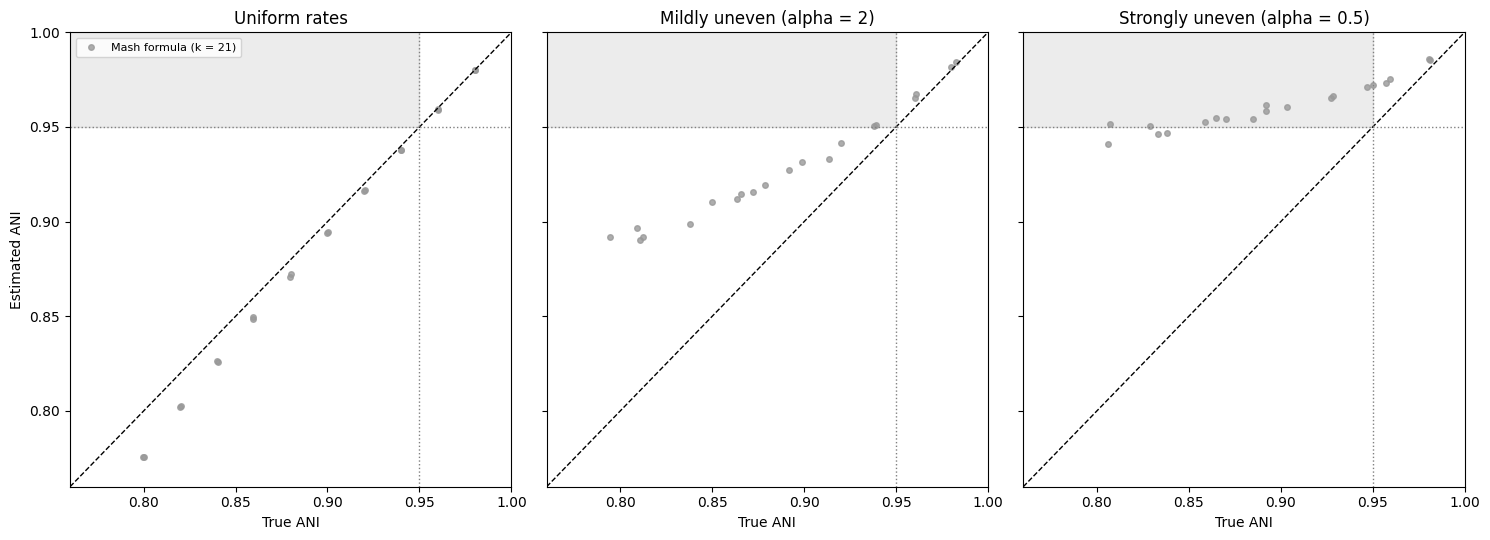

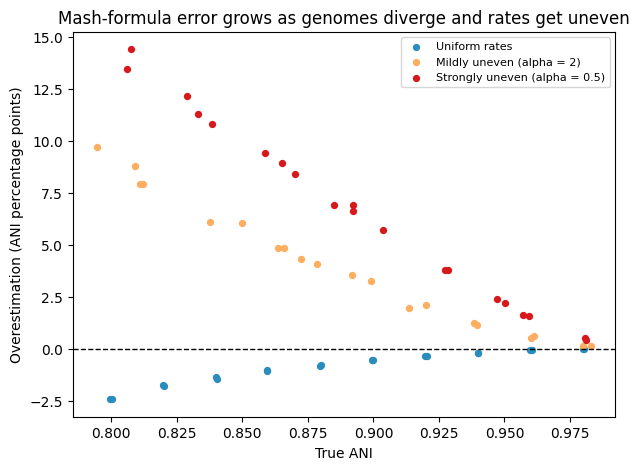

Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/exp1_summary.csv


,setting,estimator,mean error,mean |error|,max error,misclassified
0,Uniform rates,Mash formula (k = 21),-0.86,0.86,-0.01,0 / 20
1,Mildly uneven (alpha = 2),Mash formula (k = 21),3.97,3.97,9.72,2 / 20
2,Strongly uneven (alpha = 0.5),Mash formula (k = 21),6.58,6.58,14.43,12 / 20


In [10]:
BASIC_SETTINGS = {
    "Uniform rates":                 (rates_uniform,    0.0),
    "Mildly uneven (alpha = 2)":     (rates_gamma(2.0), 0.0),
    "Strongly uneven (alpha = 0.5)": (rates_gamma(0.5), 0.0),
}
df_basic = run_or_load("exp1_2_raw", BASIC_SETTINGS, seed=1)


plot_estimates(df_basic, [MASH], name="exp1_mash_vs_true")
fig, ax = plt.subplots(figsize=(7, 5))
for name, col in zip(BASIC_SETTINGS, ["#2b8cbe", "#fdae61", "#d7191c"]):
    d = df_basic[df_basic.setting == name]
    ax.scatter(d["true"], (d[MASH] - d["true"]) * 100, s=18, color=col, label=name)
ax.axhline(0, color="k", ls="--", lw=1)
ax.set_xlabel("True ANI"); ax.set_ylabel("Overestimation (ANI percentage points)")
ax.set_title("Mash-formula error grows as genomes diverge and rates get uneven")
ax.legend(fontsize=8)
plt.savefig(f"{RESULTS}/exp1_error.png", dpi=200, bbox_inches="tight")
plt.show()

summarise(df_basic, [MASH], name="exp1_summary")

**Results**

- **Uniform rates:** the formula is nearly accurate and never overestimates. Its small negative error comes from the Mash formula's approximation.
- **Uneven rates:** the formula consistently overestimates ANI.
- **The error grows** as genomes diverge and as rates become more uneven, reaching about +14 points.
- **Misclassification:** with strongly uneven rates, 12 of 20 pairs that belong to different species (true ANI < 95%) are estimated at ≥ 95%, so they would be called the same species.

**Conclusion:** uneven mutation across regions alone is enough to make k-mer ANI overestimate similarity and misclassify species. This supports H1.

##  Experiment 2: Testing our method: multi-k with gamma-distributed rates

**What we did**
- Used the same three mutation patterns as before: uniform, mildly uneven (α = 2) and strongly uneven (α = 0.5). There were 10 ANI values from 80% to 98% with 2 replicates each, giving 20 pairs per pattern.
- Counted shared k-mers at k = 15, 17, …, 31 and compared three estimators:
  - **Mash formula (k = 21):** current practice.
  - **Multi-k, uniform (control):** fits a straight line to log(shared) vs. k, so it uses the same data but ignores rate variation.
  - **Multi-k, gamma (ours):** fits log C(k) = log s − α·log(1 + k·d/α), then computes ANI = (1 + d/α)^(−α).

Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/exp2_methods.png


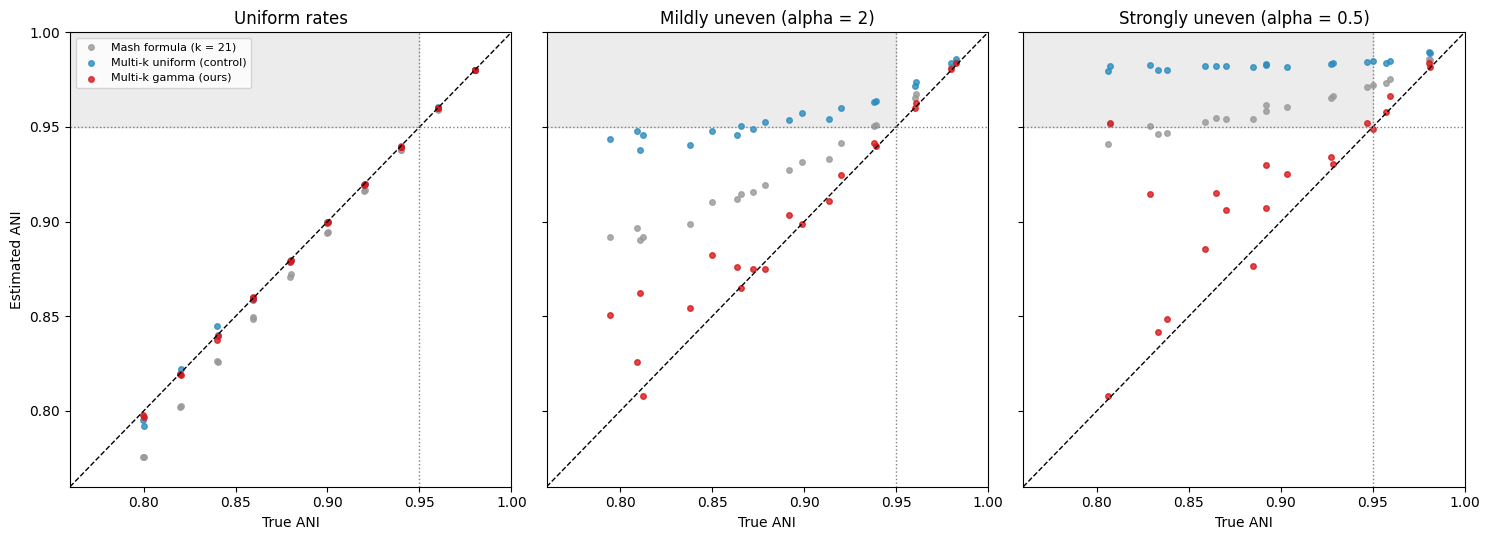

Fitted alpha (median):
setting
Uniform rates                    1000.00
Mildly uneven (alpha = 2)           2.04
Strongly uneven (alpha = 0.5)       0.50
Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/exp2_summary.csv


,setting,estimator,mean error,mean |error|,max error,misclassified
0,Uniform rates,Mash formula (k = 21),-0.86,0.86,-0.01,0 / 20
1,Uniform rates,Multi-k uniform (control),-0.04,0.13,0.49,0 / 20
2,Uniform rates,Multi-k gamma (ours),-0.06,0.06,0.04,0 / 20
3,Mildly uneven (alpha = 2),Mash formula (k = 21),3.97,3.97,9.72,2 / 20
4,Mildly uneven (alpha = 2),Multi-k uniform (control),6.74,6.74,14.89,8 / 20
5,Mildly uneven (alpha = 2),Multi-k gamma (ours),1.00,1.12,5.59,0 / 20
6,Strongly uneven (alpha = 0.5),Mash formula (k = 21),6.58,6.58,14.43,12 / 20
7,Strongly uneven (alpha = 0.5),Multi-k uniform (control),8.77,8.77,17.51,15 / 20
8,Strongly uneven (alpha = 0.5),Multi-k gamma (ours),2.27,2.36,14.48,3 / 20


In [11]:
plot_estimates(df_basic, [MASH, UNIF, GAMMA], name="exp2_methods")
print("Fitted alpha (median):")
print(df_basic.groupby("setting", sort=False)["alpha_gamma"].median().round(2).to_string())
summarise(df_basic, [MASH, UNIF, GAMMA], name="exp2_summary")

- **No harm when rates are uniform.** The gamma method is as accurate as the control, and α goes to its upper limit, correctly detecting that there is no unevenness.
- **It recovers α from k-mer counts alone** (2.04 vs. 2, and 0.50 vs. 0.5). This supports H2.
- **It reduces the error.** Compared with Mash, it is 4× lower with mildly uneven rates and 2.9× lower with strongly uneven rates. Misclassifications fall from 12 to 3 in the strongly uneven case. This supports H3.
- **The uniform control is worse than Mash.** A straight line fitted to curved data overestimates ANI even more. The improvement therefore comes from modeling rate variation, not from using more k values.

**Limitations**
- Some overestimation remains under strong unevenness (+2.3 points), and the estimates are noisy. This is likely due to the small number of regions (about 200 per 1 Mb genome) and the limited k range.
- The simulation follows the same gamma model the method assumes, so this is a best-case test. Next we need rate patterns the model doesn't assume, gene-content differences, insertions and deletions, and real genomes.

## Experiment 3: Harder simulations: patterns our model does not assume, and gene-content differences

**What we did**
- **Test 1: rate patterns not assumed by the gamma model** (no gene-content differences):
  - **Two-class:** 30% of regions mutate 5× faster than the rest.
  - **Wave:** a smooth 4-fold wave in mutation rate along the chromosome.
- **Test 2: genes present in only one genome:**
  - Gamma rates (α = 2) with **10%** or **30%** of genome B's regions replaced by unrelated sequence (true s = 0.90 and 0.70).
  - True ANI is computed over shared regions only.
- Each setting has 10 ANI values from 80% to 98% with 2 replicates, giving 20 pairs.
- Compared the Mash formula (k = 21), multi-k uniform (control) and multi-k gamma (ours).

Loaded saved results: /content/drive/MyDrive/CMPS355_ANI_Project/results/exp3_raw.csv
Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/exp3_methods.png


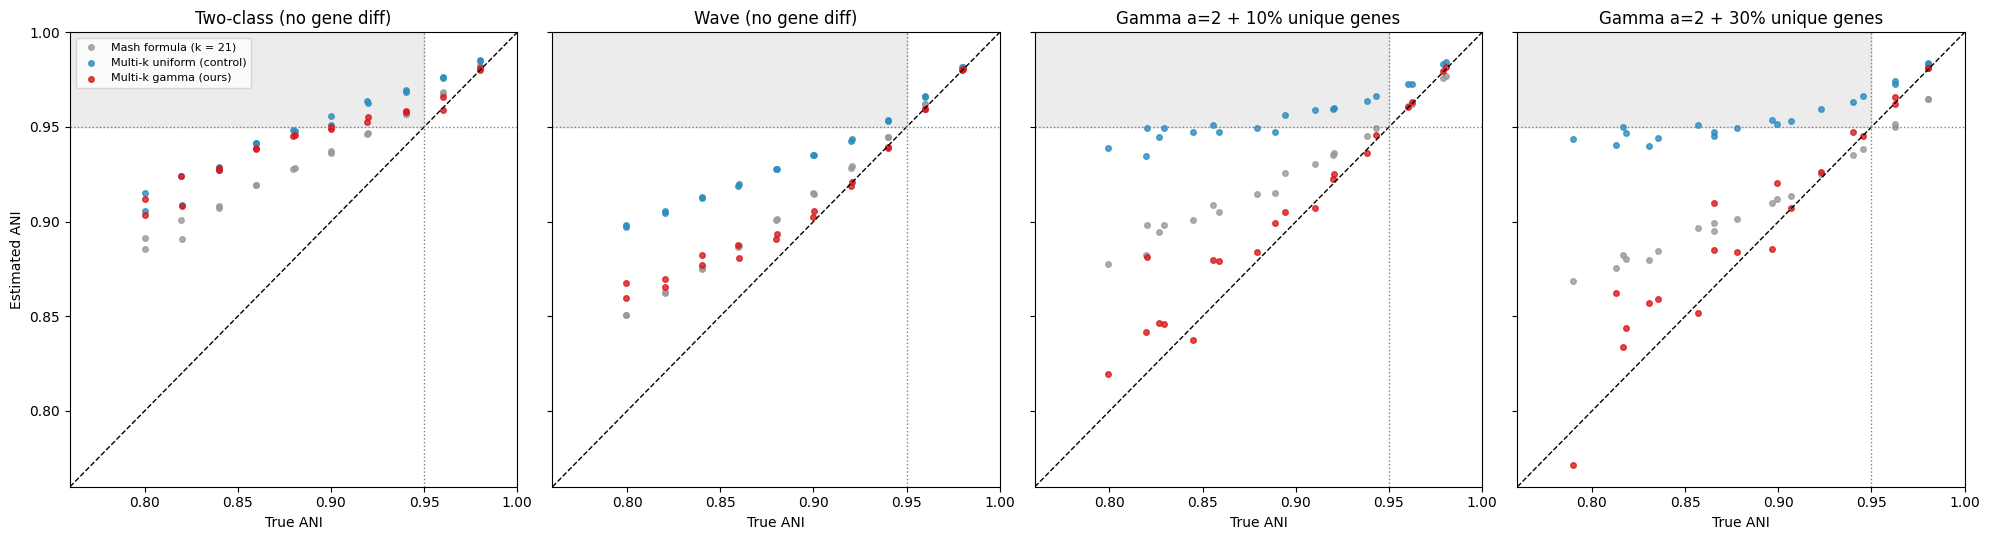

Shared fraction s: true vs. estimated (medians)
                              true_s  s_uniform  s_gamma
setting                                                 
Two-class (no gene diff)         1.0      0.716    0.753
Wave (no gene diff)              1.0      0.649    0.919
Gamma a=2 + 10% unique genes     0.9      0.539    0.878
Gamma a=2 + 30% unique genes     0.7      0.397    0.683

Fitted alpha (median):
setting
Two-class (no gene diff)        21.10
Wave (no gene diff)              5.14
Gamma a=2 + 10% unique genes     1.95
Gamma a=2 + 30% unique genes     2.14
Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/exp3_summary.csv


,setting,estimator,mean error,mean |error|,max error,misclassified
0,Two-class (no gene diff),Mash formula (k = 21),4.31,4.31,9.07,2 / 20
1,Two-class (no gene diff),Multi-k uniform (control),5.92,5.92,11.44,6 / 20
2,Two-class (no gene diff),Multi-k gamma (ours),5.40,5.41,11.12,5 / 20
3,Wave (no gene diff),Mash formula (k = 21),2.07,2.07,5.11,0 / 20
4,Wave (no gene diff),Multi-k uniform (control),4.42,4.42,9.89,2 / 20
5,Wave (no gene diff),Multi-k gamma (ours),1.90,1.93,6.77,0 / 20
6,Gamma a=2 + 10% unique genes,Mash formula (k = 21),3.32,3.39,7.86,0 / 20
7,Gamma a=2 + 10% unique genes,Multi-k uniform (control),6.53,6.53,13.99,7 / 20
8,Gamma a=2 + 10% unique genes,Multi-k gamma (ours),1.06,1.18,6.12,0 / 20
9,Gamma a=2 + 30% unique genes,Mash formula (k = 21),2.30,2.97,7.89,1 / 20


In [12]:
HARD_SETTINGS = {
    "Two-class (no gene diff)":     (rates_two_class,  0.00),
    "Wave (no gene diff)":          (rates_wave,       0.00),
    "Gamma a=2 + 10% unique genes": (rates_gamma(2.0), 0.10),
    "Gamma a=2 + 30% unique genes": (rates_gamma(2.0), 0.30),
}
df_hard = run_or_load("exp3_raw", HARD_SETTINGS, seed=3)


plot_estimates(df_hard, [MASH, UNIF, GAMMA], name="exp3_methods")
print("Shared fraction s: true vs. estimated (medians)")
print(df_hard.groupby("setting", sort=False)[["true_s", "s_uniform", "s_gamma"]].median().round(3).to_string())
print("\nFitted alpha (median):")
print(df_hard.groupby("setting", sort=False)["alpha_gamma"].median().round(2).to_string())
summarise(df_hard, [MASH, UNIF, GAMMA], name="exp3_summary")

**Key findings**
- **Gene-content differences:** the gamma method recovers s (0.88 vs. 0.90, 0.68 vs. 0.70) and α (≈ 2), and cuts the error to +1.1 points in both cases, compared with +3.3 and +2.3 for Mash, with no misclassifications. Mash's lower error at 30% is a coincidence: missing genes pull its estimate down.
- **Wave:** the gamma method stays accurate (s ≈ 0.92) and is slightly better than Mash (+1.9 vs. +2.1). The wave is only mildly uneven (α ≈ 5).
- **Two-class:** the gamma method fails (+5.4 vs. +4.3 for Mash). Almost no k-mers survive in the fast regions, so the model treats them as missing genes (s = 0.75 vs. 1.0).
- **The uniform control is always the worst** and badly underestimates s (0.40–0.72).

**Limitations**
- k-mers cannot distinguish highly divergent regions from absent ones. Smaller k does not help, because below k ≈ 15 chance matches outnumber the true matches.
- Below about 83% ANI the gamma fit becomes unstable and sometimes underestimates.

## Experiment 4: Comparison with published tools

**What we did**
- Simulated new genome pairs under all seven settings from Experiments 1–3 (uniform, gamma α = 2 and 0.5, two-class, wave, and gamma α = 2 with 10% and 30% unique genes), 20 pairs per setting.
- Ran the real published tools on each pair:
  - **Mash** v2.3 (k = 21, sketch size 10,000).
  - **skani** (via pyskani, default settings).
- Compared them with the Mash formula, the multi-k uniform control and our multi-k gamma method on exactly the same pairs.

In [13]:
# ---------------- install Mash and skani ----------------
import subprocess
subprocess.run("pip -q install pyskani", shell=True, check=True)
if not os.path.exists("/content/mash-Linux64-v2.3/mash"):
    subprocess.run("cd /content && wget -q https://github.com/marbl/Mash/releases/download/v2.3/mash-Linux64-v2.3.tar "
                   "&& tar -xf mash-Linux64-v2.3.tar", shell=True, check=True)
MASH_BIN = "/content/mash-Linux64-v2.3/mash"

import pyskani
print("Mash version:", subprocess.run([MASH_BIN, "--version"], capture_output=True, text=True).stdout.strip())

Mash version: 2.3


Loaded saved results: /content/drive/MyDrive/CMPS355_ANI_Project/results/exp4_raw.csv
Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/exp4_basic.png


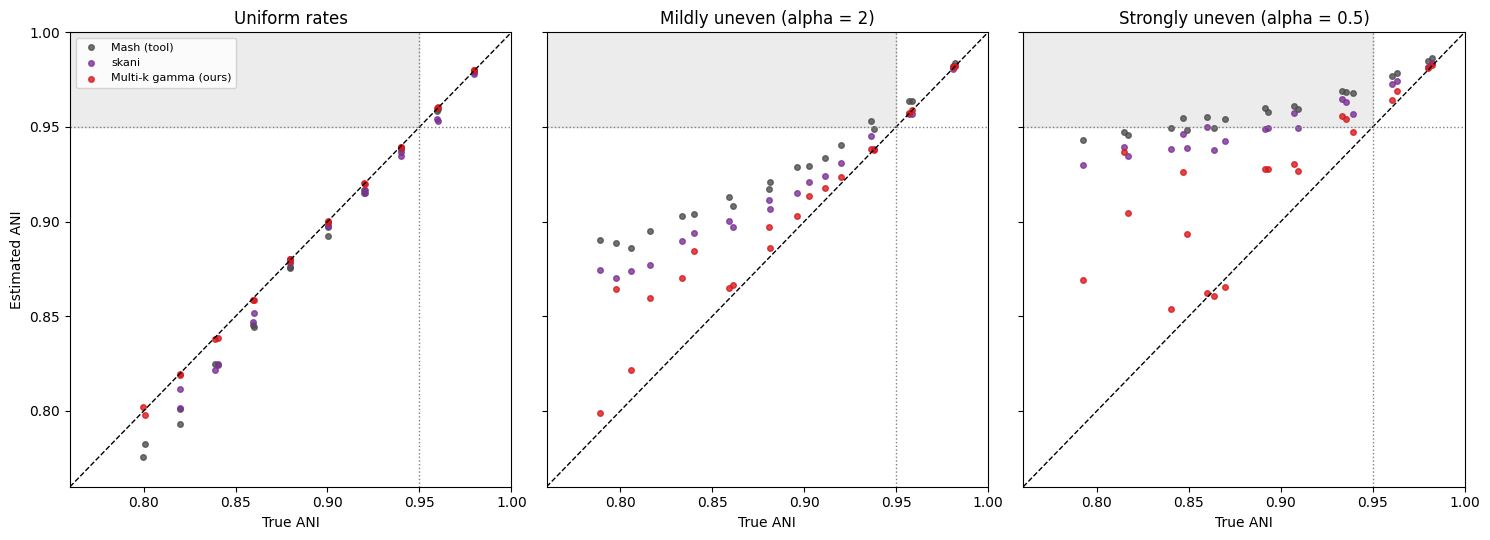

Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/exp4_hard.png


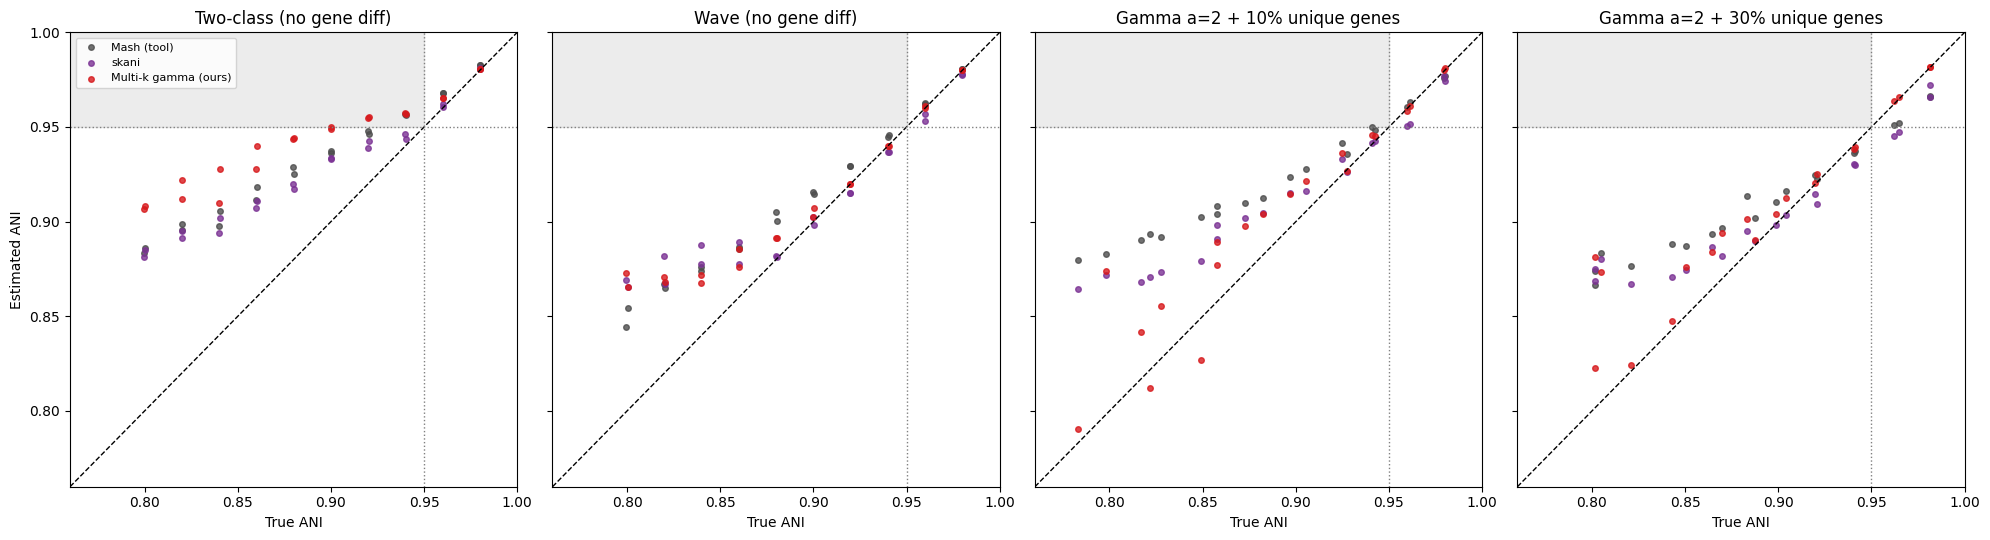

skani pairs with no estimate (true ANI too low):
setting
Uniform rates                    2
Mildly uneven (alpha = 2)        0
Strongly uneven (alpha = 0.5)    0
Two-class (no gene diff)         0
Wave (no gene diff)              0
Gamma a=2 + 10% unique genes     0
Gamma a=2 + 30% unique genes     0
Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/exp4_summary.csv


,setting,estimator,mean error,mean |error|,max error,misclassified
0,Uniform rates,Mash (tool),-0.90,0.90,-0.02,0 / 20
1,Uniform rates,skani,-0.64,0.65,0.03,0 / 20
2,Uniform rates,Mash formula (k = 21),-0.89,0.89,-0.02,0 / 20
3,Uniform rates,Multi-k uniform (control),-0.04,0.11,0.30,0 / 20
4,Uniform rates,Multi-k gamma (ours),-0.03,0.07,0.21,0 / 20
5,Mildly uneven (alpha = 2),Mash (tool),4.03,4.03,10.12,1 / 20
6,Mildly uneven (alpha = 2),skani,2.98,3.00,8.55,0 / 20
7,Mildly uneven (alpha = 2),Mash formula (k = 21),4.09,4.09,10.16,1 / 20
8,Mildly uneven (alpha = 2),Multi-k uniform (control),6.83,6.83,15.82,7 / 20
9,Mildly uneven (alpha = 2),Multi-k gamma (ours),1.39,1.40,6.68,0 / 20


In [14]:
# ---------------- tool wrappers ----------------
SIM_DIR = "/content/sim"
os.makedirs(SIM_DIR, exist_ok=True)
DECODE = np.frombuffer(b"ACGT", dtype=np.uint8)

def to_bytes(seq):
    return DECODE[seq].tobytes()

def write_fasta(path, seq):
    with open(path, "wb") as f:
        f.write(b">seq\n" + to_bytes(seq) + b"\n")

# genome A: sketch once for both tools
fa_A = f"{SIM_DIR}/A.fa"
write_fasta(fa_A, genome_A)
subprocess.run([MASH_BIN, "sketch", "-k", "21", "-s", "10000", "-o", f"{SIM_DIR}/A", fa_A],
               capture_output=True, check=True)
skani_db = pyskani.Database()
skani_db.sketch("A", to_bytes(genome_A))

def mash_tool(B):
    fa_B = f"{SIM_DIR}/B.fa"
    write_fasta(fa_B, B)
    out = subprocess.run([MASH_BIN, "dist", f"{SIM_DIR}/A.msh", fa_B],
                         capture_output=True, text=True, check=True).stdout
    return 1 - float(out.split("\t")[2])     # Mash reports distance; ANI = 1 - distance

def skani_tool(B):
    hits = skani_db.query("B", to_bytes(B))
    return hits[0].identity if hits else np.nan   # skani gives no hit below ~80% ANI

MASH_TOOL, SKANI = "Mash (tool)", "skani"
COLORS[MASH_TOOL] = "#4d4d4d"
COLORS[SKANI] = "#7b3294"


def run_experiment_tools(settings):
    rows = []
    for name, (rate_fn, gene_diff) in settings.items():
        print("Running:", name)
        for target in TARGET_ANIS:
            for _ in range(REPLICATES):
                B, true_ani, true_s = make_pair(1 - target, rate_fn, gene_diff)
                C = shared_fractions(B)
                g_ani, g_s, g_alpha = est_gamma(C)
                rows.append({"setting": name, "true": true_ani, "true_s": true_s,
                             MASH_TOOL: mash_tool(B), SKANI: skani_tool(B),
                             MASH: est_mash(C), UNIF: est_uniform(C)[0], GAMMA: g_ani,
                             "s_gamma": g_s, "alpha_gamma": g_alpha})
    return pd.DataFrame(rows)

ALL_SETTINGS = {**BASIC_SETTINGS, **HARD_SETTINGS}
path = f"{RESULTS}/exp4_raw.csv"
if os.path.exists(path):
    df_tools = pd.read_csv(path)
    print("Loaded saved results:", path)
else:
    rng = np.random.default_rng(4)           # fixed seed
    df_tools = run_experiment_tools(ALL_SETTINGS)
    df_tools.to_csv(path, index=False)
    print("Ran and saved:", path)

# ---------------- results ----------------
plot_estimates(df_tools[df_tools.setting.isin(BASIC_SETTINGS)], [MASH_TOOL, SKANI, GAMMA], name="exp4_basic")
plot_estimates(df_tools[df_tools.setting.isin(HARD_SETTINGS)],  [MASH_TOOL, SKANI, GAMMA], name="exp4_hard")

print("skani pairs with no estimate (true ANI too low):")
print(df_tools.groupby("setting", sort=False)[SKANI].apply(lambda x: x.isna().sum()).to_string())

summarise(df_tools, [MASH_TOOL, SKANI, MASH, UNIF, GAMMA], name="exp4_summary")

**Key findings**
- **Mash (tool) matches our Mash formula** to within 0.1 points in every setting, which confirms that Experiments 1–3 used a faithful reimplementation.
- **skani reduces Mash's bias but does not remove it.** It still overestimates by +3.0 and +6.1 points under uneven rates, because its correction does not model rate variation.
- **Our method is the most accurate in 4 of 7 settings.** Under strongly uneven rates it halves skani's error (+3.0 vs. +6.1) and has the fewest misclassifications (2 vs. 4 for skani and 10 for Mash).
- **Wave and 30% unique genes are near-ties with skani.** skani's lower mean error at 30% comes from errors in both directions cancelling out: its mean |error| is higher (2.29 vs. 1.47) and it misclassifies 2 pairs, while ours misclassifies none.
- **Two-class remains our weakness** (+5.3 vs. +3.6 for skani), for the same reason as in Experiment 3: highly divergent regions look like missing genes.
- **The control is the worst in every uneven setting**, confirming again that the gain comes from modeling rate variation.

## Experiment 5: Real bacterial genomes

**What we did**
- Downloaded complete RefSeq genomes from NCBI for four groups of closely related species (3 strains per species): *Escherichia* (5 species), *Klebsiella* (6), the *Bacillus cereus* group (5) and the *Streptococcus mitis* group (4).
- Within each group, selected up to 20 pairs spread across four Mash-ANI bins (78–85, 85–90, 90–95, 95–99.5%).
- Computed reference ANI by whole-genome alignment (MUMmer `dnadiff`, average identity of 1-to-1 alignments).
- Ran Mash, skani, the multi-k uniform control and our multi-k gamma method on every pair.
- Kept pairs with reference ANI of 80–99% where at least 50% of both genomes aligned (otherwise the reference is unreliable), and compared all tools on the same pairs.
- A first attempt that sampled one genome per species across whole genera was discarded: most pairs aligned over only 5–27% of the genome.

In [15]:
TOOLS = "/content/tools"
os.makedirs(TOOLS, exist_ok=True)

DATASETS_BIN = f"{TOOLS}/datasets"
if not os.path.exists(DATASETS_BIN):
    subprocess.run(f"wget -q -O '{DATASETS_BIN}' "
                   "https://ftp.ncbi.nlm.nih.gov/pub/datasets/command-line/v2/linux-amd64/datasets",
                   shell=True, check=True)
subprocess.run(["chmod", "+x", DATASETS_BIN])
subprocess.run("apt-get -qq update > /dev/null && apt-get -qq install -y mummer > /dev/null",
               shell=True, check=True)
print(subprocess.run([DATASETS_BIN, "--version"], capture_output=True, text=True).stdout.strip())
print(subprocess.run("which nucmer dnadiff", shell=True, capture_output=True, text=True).stdout)

datasets version: 18.40.0
/usr/bin/nucmer
/usr/bin/dnadiff



In [16]:
import json, zipfile, shutil

# Groups of closely related species, so that pairs span ~80-99% ANI
# AND share most of their genome (otherwise the alignment reference is unreliable).
GROUPS = {
    "Escherichia":           ["Escherichia coli", "Escherichia fergusonii", "Escherichia albertii",
                              "Escherichia marmotae", "Escherichia ruysiae"],
    "Klebsiella":            ["Klebsiella pneumoniae", "Klebsiella quasipneumoniae", "Klebsiella variicola",
                              "Klebsiella oxytoca", "Klebsiella michiganensis", "Klebsiella grimontii"],
    "Bacillus cereus group": ["Bacillus cereus", "Bacillus thuringiensis", "Bacillus anthracis",
                              "Bacillus mycoides", "Bacillus cytotoxicus"],
    "Streptococcus mitis group": ["Streptococcus pneumoniae", "Streptococcus mitis",
                                  "Streptococcus pseudopneumoniae", "Streptococcus oralis"],
}
STRAINS_PER_SPECIES = 3          # several strains per species -> same-species pairs (>95%) too

V = "v2"                          # new file names, so the first (bad) selection is kept for the record
GENOME_DIR  = f"{DATA}/genomes"   # downloads are shared between versions
GENOME_LIST = f"{DATA}/{V}_genomes.csv"
PAIR_LIST   = f"{DATA}/{V}_pairs.csv"
REF_FILE    = f"{DATA}/{V}_reference_ani.csv"

def ncbi_summary(taxon, limit=100):
    r = subprocess.run([DATASETS_BIN, "summary", "genome", "taxon", taxon,
                        "--assembly-level", "complete", "--assembly-source", "RefSeq",
                        "--limit", str(limit), "--as-json-lines"],
                       capture_output=True, text=True)
    return [json.loads(line) for line in r.stdout.splitlines() if line.strip()]

def download_genomes(accessions, outdir):
    os.makedirs(outdir, exist_ok=True)
    todo = [a for a in accessions if not os.path.exists(f"{outdir}/{a}.fna")]
    for i in range(0, len(todo), 20):                       # download in batches of 20
        batch = todo[i:i + 20]
        zip_path = "/content/ncbi_tmp.zip"
        subprocess.run([DATASETS_BIN, "download", "genome", "accession", *batch,
                        "--include", "genome", "--filename", zip_path], check=True, capture_output=True)
        with zipfile.ZipFile(zip_path) as z:
            for name in z.namelist():
                if name.endswith(".fna"):
                    acc = name.split("/")[-2]
                    with z.open(name) as src, open(f"{outdir}/{acc}.fna", "wb") as dst:
                        shutil.copyfileobj(src, dst)
        os.remove(zip_path)
        print(f"Downloaded {min(i + 20, len(todo))}/{len(todo)}")

if os.path.exists(GENOME_LIST):
    genomes = pd.read_csv(GENOME_LIST)
    print("Loaded genome list:", GENOME_LIST)
else:
    rows = []
    for group, species_list in GROUPS.items():
        for sp in species_list:
            accs = sorted(r["accession"] for r in ncbi_summary(sp))[:STRAINS_PER_SPECIES]
            if not accs:
                print("  no complete RefSeq genome found for", sp)
            rows += [{"genus": group, "species": sp, "accession": a} for a in accs]
    genomes = pd.DataFrame(rows)
    genomes.to_csv(GENOME_LIST, index=False)
    print("Chose genomes and saved list:", GENOME_LIST)

download_genomes(list(genomes.accession), GENOME_DIR)
genomes["path"] = [f"{GENOME_DIR}/{a}.fna" for a in genomes.accession]
print(genomes.groupby(["genus", "species"]).size().to_string())

Loaded genome list: /content/drive/MyDrive/CMPS355_ANI_Project/data/v2_genomes.csv
genus                      species                       
Bacillus cereus group      Bacillus anthracis                3
                           Bacillus cereus                   3
                           Bacillus cytotoxicus              3
                           Bacillus mycoides                 3
                           Bacillus thuringiensis            3
Escherichia                Escherichia albertii              3
                           Escherichia coli                  3
                           Escherichia fergusonii            3
                           Escherichia marmotae              3
                           Escherichia ruysiae               2
Klebsiella                 Klebsiella grimontii              3
                           Klebsiella michiganensis          3
                           Klebsiella oxytoca                3
                           Klebsiella pn

In [17]:
# ---------------- reading real genomes and counting canonical k-mers ----------------
# Real genomes have several contigs, non-ACGT letters and two DNA strands:
# a k-mer and its reverse complement count as the same ("canonical" k-mer).
LOOKUP = np.full(256, 4, dtype=np.uint8)
for i, b in enumerate(b"ACGT"):
    LOOKUP[b] = i
for i, b in enumerate(b"acgt"):
    LOOKUP[b] = i

def read_fasta(path):
    contigs, cur = [], []
    with open(path, "rb") as f:
        for line in f:
            if line.startswith(b">"):
                if cur:
                    contigs.append(b"".join(cur)); cur = []
            else:
                cur.append(line.strip())
    if cur:
        contigs.append(b"".join(cur))
    return contigs

def encode(contig):
    return LOOKUP[np.frombuffer(contig, dtype=np.uint8)]

def pack(seq, k):
    n = len(seq) - k + 1
    vals = np.zeros(n, dtype=np.uint64)
    for j in range(k):
        vals = (vals << np.uint64(2)) | (seq[j:j + n] & 3).astype(np.uint64)
    return vals

def canonical_kmer_set(contigs_enc, k):
    out = []
    for s in contigs_enc:
        if len(s) < k:
            continue
        fwd = pack(s, k)
        rev = pack(np.ascontiguousarray((3 - (s & 3))[::-1]), k)[::-1]
        c = np.concatenate([[0], np.cumsum(s == 4)])
        ok = (c[k:] - c[:-k]) == 0
        out.append(np.minimum(fwd, rev)[ok])
    return np.unique(np.concatenate(out))

def shared_fractions_real(encA, encB):
    out = []
    for k in KS:
        kA = canonical_kmer_set(encA, k)
        kB = canonical_kmer_set(encB, k)
        shared = np.intersect1d(kA, kB, assume_unique=True).size
        chance = kA.size * kB.size / (4.0 ** k / 2)
        out.append(max(shared - chance, 1) / kA.size)
    return np.array(out)

In [18]:
BINS = [(0.78, 0.85), (0.85, 0.90), (0.90, 0.95), (0.95, 0.995)]   # Mash-ANI bins
PAIRS_PER_BIN = 5                                                  # -> up to 20 pairs per group
WORK = "/content/work"
os.makedirs(WORK, exist_ok=True)

def mash_all_vs_all(paths):
    subprocess.run([MASH_BIN, "sketch", "-k", "21", "-s", "10000", "-o", f"{WORK}/all", *paths],
                   capture_output=True, check=True)
    out = subprocess.run([MASH_BIN, "dist", f"{WORK}/all.msh", f"{WORK}/all.msh"],
                         capture_output=True, text=True, check=True).stdout
    d = {}
    for line in out.splitlines():
        a, b, dist = line.split("\t")[:3]
        d[(a, b)] = 1 - float(dist)
    return d

if os.path.exists(PAIR_LIST):
    pairs = pd.read_csv(PAIR_LIST)
    print("Loaded pair list:", PAIR_LIST)
else:
    rows = []
    for group, g in genomes.groupby("genus"):
        mash = mash_all_vs_all(list(g.path))
        recs = g.to_dict("records")
        cand = [(mash[(recs[i]["path"], recs[j]["path"])], recs[i], recs[j])
                for i in range(len(recs)) for j in range(i + 1, len(recs))]
        for lo, hi in BINS:                                        # spread pairs across the ANI range
            in_bin = sorted([c for c in cand if lo <= c[0] < hi], key=lambda c: c[0])
            if len(in_bin) > PAIRS_PER_BIN:
                idx = np.unique(np.linspace(0, len(in_bin) - 1, PAIRS_PER_BIN).round().astype(int))
                in_bin = [in_bin[i] for i in idx]
            for m, a, b in in_bin:
                rows.append({"genus": group, "acc_a": a["accession"], "acc_b": b["accession"],
                             "species_a": a["species"], "species_b": b["species"],
                             "path_a": a["path"], "path_b": b["path"], "mash_tool": m})
    pairs = pd.DataFrame(rows)
    pairs.to_csv(PAIR_LIST, index=False)
    print("Chose pairs and saved list:", PAIR_LIST)
print(pairs.groupby("genus").size().to_string())

# ---- reference ANI by whole-genome alignment (saved after every pair) ----
def dnadiff_ani(fa1, fa2, prefix):
    subprocess.run(["dnadiff", "-p", prefix, fa1, fa2], capture_output=True, check=True)
    ani = aligned1 = aligned2 = None
    in_one_to_one = False
    for line in open(prefix + ".report"):
        if line.startswith("AlignedBases") and aligned1 is None:
            p = line.split()
            aligned1 = float(p[1].split("(")[1].rstrip("%)")) / 100
            aligned2 = float(p[2].split("(")[1].rstrip("%)")) / 100
        if line.startswith("1-to-1"):
            in_one_to_one = True
        if in_one_to_one and line.startswith("AvgIdentity"):
            ani = float(line.split()[1]) / 100
            break
    return ani, aligned1, aligned2

done = pd.read_csv(REF_FILE) if os.path.exists(REF_FILE) else pd.DataFrame(columns=["acc_a", "acc_b"])
done_keys = set(zip(done.acc_a, done.acc_b))
for n, p in enumerate(pairs.itertuples(), 1):
    if (p.acc_a, p.acc_b) in done_keys:
        continue
    ani, al_a, al_b = dnadiff_ani(p.path_a, p.path_b, f"{WORK}/dd")
    row = pd.DataFrame([{"acc_a": p.acc_a, "acc_b": p.acc_b, "ref_ani": ani,
                         "aligned_a": al_a, "aligned_b": al_b}])
    row.to_csv(REF_FILE, mode="a", header=not os.path.exists(REF_FILE), index=False)
    print(f"[{n}/{len(pairs)}] {p.genus}: {p.species_a} vs {p.species_b} -> ANI {ani:.4f}, aligned {al_a:.0%}")
reference = pd.read_csv(REF_FILE)

Loaded pair list: /content/drive/MyDrive/CMPS355_ANI_Project/data/v2_pairs.csv
genus
Bacillus cereus group        15
Escherichia                  15
Klebsiella                   15
Streptococcus mitis group    15


Valid pairs per group (80-99% ANI, >= 50% aligned, all tools gave an estimate):
genus
Bacillus cereus group         9
Escherichia                  15
Klebsiella                   10
Streptococcus mitis group    15
Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/v2_exp5_real.png


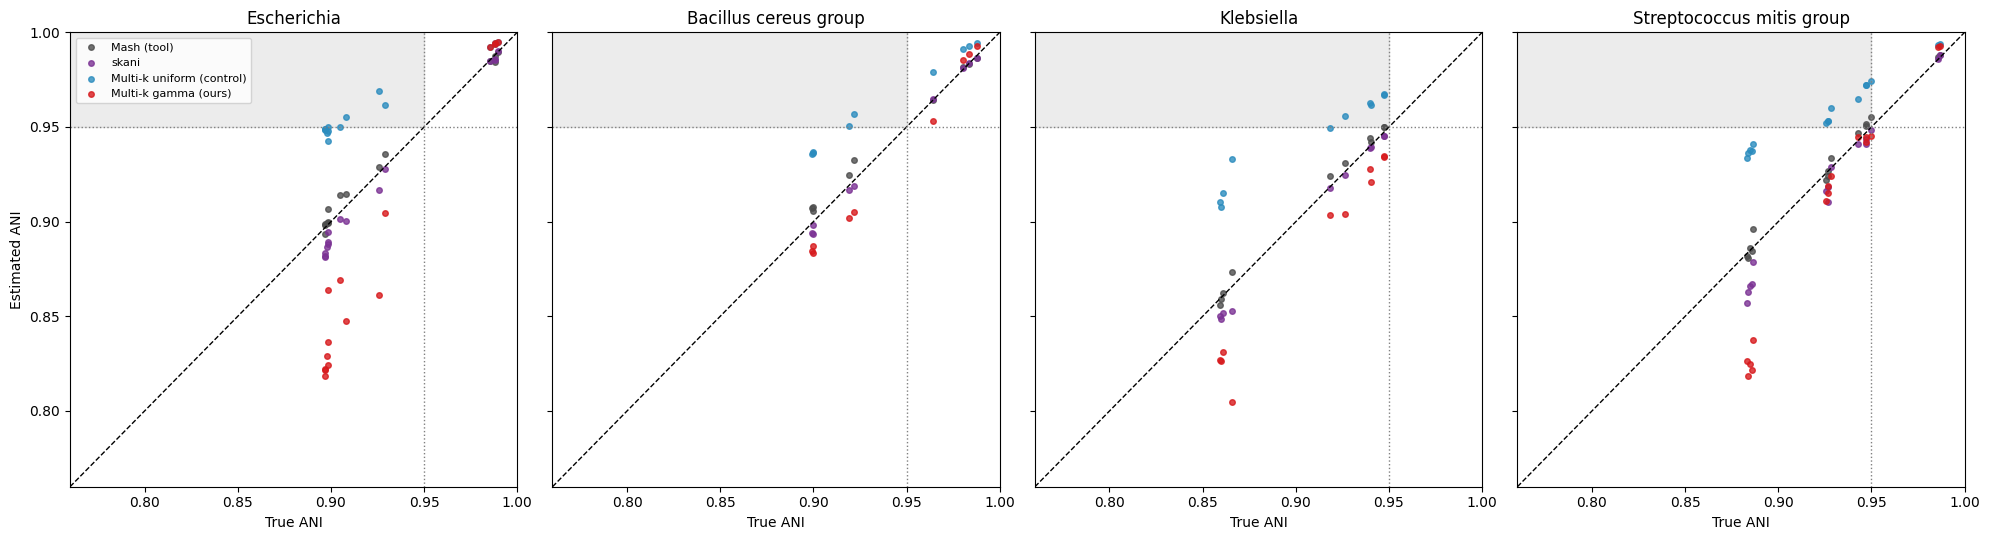

Fitted alpha (median):
genus
Bacillus cereus group        1.75
Escherichia                  1.68
Klebsiella                   2.01
Streptococcus mitis group    2.10
Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/v2_exp5_summary.csv


,setting,estimator,mean error,mean |error|,max error,misclassified
0,Escherichia,Mash (tool),0.22,0.33,0.89,0 / 15
1,Escherichia,skani,-0.70,0.71,0.05,0 / 15
2,Escherichia,Multi-k uniform (control),3.61,3.61,5.20,4 / 15
3,Escherichia,Multi-k gamma (ours),-4.19,4.51,0.71,0 / 15
4,Bacillus cereus group,Mash (tool),0.42,0.45,1.05,0 / 9
5,Bacillus cereus group,skani,-0.21,0.24,0.08,0 / 9
6,Bacillus cereus group,Multi-k uniform (control),2.42,2.42,3.72,2 / 9
7,Bacillus cereus group,Multi-k gamma (ours),-0.82,1.15,0.53,0 / 9
8,Klebsiella,Mash (tool),0.27,0.35,0.77,1 / 10
9,Klebsiella,skani,-0.50,0.50,-0.04,0 / 10


In [19]:
EXP5_RAW = f"{RESULTS}/{V}_exp5_raw.csv"
data = pairs.merge(reference, on=["acc_a", "acc_b"])

done = pd.read_csv(EXP5_RAW) if os.path.exists(EXP5_RAW) else pd.DataFrame(columns=["acc_a", "acc_b"])
done_keys = set(zip(done.acc_a, done.acc_b))
for n, p in enumerate(data.itertuples(), 1):
    if (p.acc_a, p.acc_b) in done_keys:
        continue
    contigs_a, contigs_b = read_fasta(p.path_a), read_fasta(p.path_b)
    if sum(map(len, contigs_a)) > sum(map(len, contigs_b)):    # A = smaller genome
        contigs_a, contigs_b = contigs_b, contigs_a
    C = shared_fractions_real([encode(c) for c in contigs_a], [encode(c) for c in contigs_b])
    g_ani, g_s, g_alpha = est_gamma(C)
    db = pyskani.Database()
    db.sketch("A", *contigs_a)
    hits = db.query("B", *contigs_b)
    row = pd.DataFrame([{"genus": p.genus, "acc_a": p.acc_a, "acc_b": p.acc_b,
                         "species_a": p.species_a, "species_b": p.species_b,
                         "ref_ani": p.ref_ani, "aligned_a": p.aligned_a, "aligned_b": p.aligned_b,
                         MASH_TOOL: p.mash_tool, SKANI: hits[0].identity if hits else np.nan,
                         UNIF: est_uniform(C)[0], GAMMA: g_ani,
                         "s_gamma": g_s, "alpha_gamma": g_alpha}])
    row.to_csv(EXP5_RAW, mode="a", header=not os.path.exists(EXP5_RAW), index=False)
    print(f"[{n}/{len(data)}] {p.genus}: ref {p.ref_ani:.4f} | ours {g_ani:.4f}")

# ---- results ----
df_real = pd.read_csv(EXP5_RAW)
df_real["setting"] = df_real["genus"]
df_real["true"] = df_real["ref_ani"]
df_real = df_real[(df_real["true"] >= 0.80) & (df_real["true"] <= 0.99)]
df_real = df_real[df_real[["aligned_a", "aligned_b"]].min(axis=1) >= 0.5]   # reference only reliable if >= 50% aligns
df_real = df_real.dropna(subset=[MASH_TOOL, SKANI, UNIF, GAMMA])            # same pairs for every tool
print("Valid pairs per group (80-99% ANI, >= 50% aligned, all tools gave an estimate):")
print(df_real.groupby("genus").size().to_string())

plot_estimates(df_real, [MASH_TOOL, SKANI, UNIF, GAMMA], name=f"{V}_exp5_real")
print("Fitted alpha (median):")
print(df_real.groupby("genus")["alpha_gamma"].median().round(2).to_string())
summarise(df_real, [MASH_TOOL, SKANI, UNIF, GAMMA], name=f"{V}_exp5_summary")

                    genus                      species_a                      species_b  true  aligned_a  s_gamma  alpha_gamma  Multi-k gamma (ours)  skani    err
              Escherichia         Escherichia fergusonii           Escherichia albertii 0.897      0.515    1.000        1.569                 0.818  0.881 -7.859
              Escherichia         Escherichia fergusonii           Escherichia albertii 0.897      0.589    1.000        1.579                 0.822  0.883 -7.524
              Escherichia         Escherichia fergusonii           Escherichia albertii 0.897      0.587    1.000        1.589                 0.822  0.882 -7.456
              Escherichia         Escherichia fergusonii           Escherichia albertii 0.898      0.520    1.000        1.540                 0.824  0.889 -7.406
              Escherichia         Escherichia fergusonii           Escherichia marmotae 0.898      0.538    1.000        1.688                 0.829  0.887 -6.879
Streptococcus mitis gr

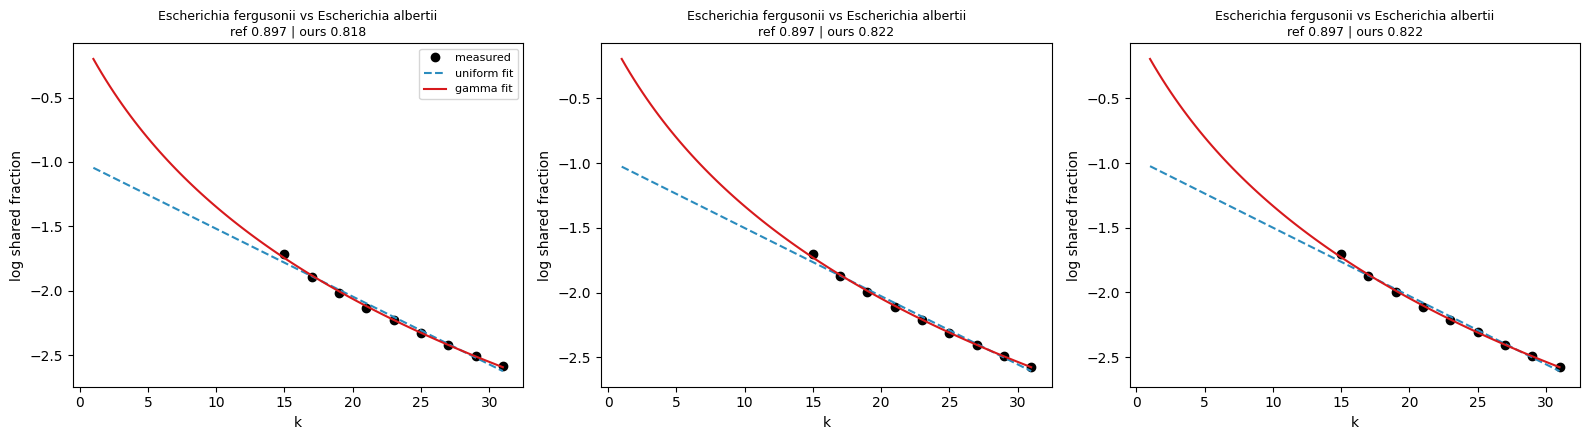

In [20]:
# ---------------- diagnostic: why does the gamma fit fail on real genomes? ----------------
diag = df_real.assign(err=(df_real[GAMMA] - df_real["true"]) * 100)
print(diag[["genus", "species_a", "species_b", "true", "aligned_a", "s_gamma",
            "alpha_gamma", GAMMA, SKANI, "err"]].sort_values("err").round(3).to_string(index=False))

# plot the measured k-mer curve and both fits for the 3 worst pairs
worst = diag.sort_values("err").head(3)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, p in zip(axes, worst.itertuples()):
    row = data[(data.acc_a == p.acc_a) & (data.acc_b == p.acc_b)].iloc[0]
    ca, cb = read_fasta(row.path_a), read_fasta(row.path_b)
    if sum(map(len, ca)) > sum(map(len, cb)):
        ca, cb = cb, ca
    C = shared_fractions_real([encode(c) for c in ca], [encode(c) for c in cb])
    _, s_u, d_u = est_uniform(C)
    g_ani, s_g, a_g = est_gamma(C)
    y = np.log(C)
    p_g, _ = curve_fit(gamma_model, KS, y, p0=[s_g, 0.05, a_g],
                       bounds=([1e-6, 1e-6, 0.01], [1, 3, 1000]), maxfev=20000)
    kk = np.linspace(1, 31, 100)
    ax.plot(KS, y, "ko", label="measured")
    ax.plot(kk, np.log(s_u) - d_u * kk, "--", color=COLORS[UNIF], label="uniform fit")
    ax.plot(kk, gamma_model(kk, *p_g), "-", color=COLORS[GAMMA], label="gamma fit")
    ax.set_title(f"{p.species_a} vs {p.species_b}\nref {p.true:.3f} | ours {g_ani:.3f}", fontsize=9)
    ax.set_xlabel("k"); ax.set_ylabel("log shared fraction")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{RESULTS}/{V}_exp5_diagnostic.png", dpi=200, bbox_inches="tight")
plt.show()

**Key findings (real genomes, 49 valid pairs)**
- **Mash slightly overestimates ANI in every group** (+0.2 to +0.4 points) and misclassifies 4 pairs at the 95% threshold. The bias predicted by H1 exists on real genomes but is much smaller than in simulations.
- **skani is the most accurate** (mean |error| 0.2–0.9, no misclassifications).
- **Our method underestimates ANI** (−0.8 to −4.2 points by group), and the error grows with divergence: it is accurate near 94–99% ANI but up to 8 points too low around 86–90%. It misclassified no pairs, partly because its errors go in the other direction.
- **The cause is the shared-fraction estimate.** In 28 of 49 pairs the fitted s is stuck at its upper limit (1.0), and these pairs have errors of −1.2 to −7.9 points. When s is estimated freely, the error is only −1.4 to +0.7 points. From k = 15–31 alone, the model cannot separate genes missing from one genome from extra mutations, so it converts missing genes into lower ANI.
- **The uniform control is the worst** (+2.4 to +3.7 points, 19 misclassified), which confirms that modeling rate variation is necessary.
- **Fitted α is consistent across genera** (about 1.7–2.1), suggesting a similar degree of rate variation in real bacteria, although it may be distorted when s is stuck at 1.



**Next steps**
- Add a fifth estimator that estimates the shared fraction s independently (fraction of 1 kb windows in A containing shared k-mers), then fits only d and α.
- Re-run it on Experiments 1–4 to check it does not break the simulation results, and keep the original method in all tables.
- Add extra pairs near the 95% threshold (93–97% ANI) to compare misclassification with more than a handful of cases.
- Write up the real-data results honestly: the bias exists but is small, and the original correction does not transfer to real genomes because of the shared-fraction problem.